# 03 · Backtest rodada a rodada (2023–2025)

Pra cada rodada de 2023, 2024 e 2025:
1. o modelo é treinado com **todos os jogos disputados antes** do primeiro jogo da rodada
2. prevê os 10 jogos da rodada

São 1.140 previsões por modelo, todas feitas sem saber o resultado. Os hiperparâmetros (k e mando do Elo, meia-vida do Dixon-Coles) e a escolha do modelo final foram feitos antes, numa validação com 2020–2022, sem olhar esses anos.

**Métricas** (quanto menor, melhor, exceto acurácia):
- **RPS** (*Ranked Probability Score*): a métrica padrão pra previsão de futebol. Leva em conta que errar "vitória" por "empate" é menos grave que errar por "derrota"
- **log-loss**: pune muito quem dá probabilidade baixa pro que aconteceu
- **Brier**: erro quadrático das probabilidades
- **acurácia**: % de jogos em que o resultado mais provável aconteceu (a menos informativa: o empate quase nunca é o mais provável)

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 200)

# paleta categórica validada (daltonismo) + rampa sequencial azul
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3b3b38",
    "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
    "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
})

In [2]:
from brasileirao import load_all, build_features, walk_forward, summarize

df, _ = build_features(load_all())
preds = walk_forward(df, temporadas=(2023, 2024, 2025))   # ~1–2 min
preds.to_csv("../results/previsoes_backtest.csv", index=False)
ordem = list(preds["modelo"].unique())
res = summarize(preds).set_index("modelo").loc[ordem]
res.round(4)

temporada 2023 ok


temporada 2024 ok


temporada 2025 ok


,jogos,log_loss,rps,brier,acuracia
modelo,,,,,
Baseline (frequência),1140,1.0531,0.2206,0.6346,0.4816
Elo + regressão logística,1140,1.0211,0.2099,0.6122,0.4930
Dixon-Coles (Poisson),1140,1.0165,0.2088,0.6088,0.4921
Gradient Boosting (Elo + forma),1140,1.0306,0.2119,0.6171,0.4974
Média (Dixon-Coles + Elo),1140,1.0160,0.2084,0.6084,0.4991


In [3]:
base = res.loc["Baseline (frequência)", "rps"]
melhora = ((base - res["rps"]) / base * 100).round(1).rename("melhora no RPS vs baseline (%)")
melhora

modelo
Baseline (frequência)              0.0
Elo + regressão logística          4.8
Dixon-Coles (Poisson)              5.4
Gradient Boosting (Elo + forma)    3.9
Média (Dixon-Coles + Elo)          5.5
Name: melhora no RPS vs baseline (%), dtype: float64

In [4]:
por_temp = summarize(preds, ("modelo", "temporada")).pivot(index="modelo", columns="temporada", values="rps").loc[ordem]
por_temp.round(4)

temporada,2023,2024,2025
modelo,,,
Baseline (frequência),0.2240,0.2213,0.2165
Elo + regressão logística,0.2180,0.2100,0.2017
Dixon-Coles (Poisson),0.2165,0.2114,0.1983
Gradient Boosting (Elo + forma),0.2200,0.2135,0.2023
Média (Dixon-Coles + Elo),0.2164,0.2098,0.1991


## Os modelos ganham do baseline em todas as temporadas?

Bootstrap por rodada: sorteia rodadas com reposição 2.000 vezes e calcula a diferença de RPS do modelo pro baseline. Se o intervalo de 95% não cruza o zero, a diferença não é sorte.

In [5]:
from brasileirao.models import CLASSES

def rps_por_jogo(g):
    """RPS de cada jogo (a função do backtest devolve só a média)."""
    p = g[["p_H", "p_D", "p_A"]].to_numpy()
    y = np.array([CLASSES.index(r) for r in g["resultado"]])
    cp = np.cumsum(p, 1)[:, :2]; co = np.cumsum(np.eye(3)[y], 1)[:, :2]
    return np.sum((cp - co) ** 2, 1) / 2

preds["rps"] = 0.0
for m in ordem:
    idx = preds["modelo"] == m
    preds.loc[idx, "rps"] = rps_por_jogo(preds[idx])

wide = preds.pivot_table(index=["temporada", "rodada", "jogo"], columns="modelo", values="rps")
rodadas = wide.groupby(level=[0, 1]).sum()
n_jogos = wide.groupby(level=[0, 1]).size()
rng = np.random.default_rng(0)
B = rng.integers(0, len(rodadas), size=(2000, len(rodadas)))
linhas = []
for m in ordem[1:]:
    diff = (rodadas["Baseline (frequência)"] - rodadas[m]).to_numpy()
    boot = diff[B].sum(1) / n_jogos.to_numpy()[B].sum(1)
    linhas.append({"modelo": m, "ganho RPS médio": diff.sum() / n_jogos.sum(),
                   "IC 95% inf": np.percentile(boot, 2.5), "IC 95% sup": np.percentile(boot, 97.5)})
pd.DataFrame(linhas).set_index("modelo").round(4)

,ganho RPS médio,IC 95% inf,IC 95% sup
modelo,,,
Elo + regressão logística,0.0107,0.0066,0.0148
Dixon-Coles (Poisson),0.0118,0.0069,0.0169
Gradient Boosting (Elo + forma),0.0087,0.0035,0.0138
Média (Dixon-Coles + Elo),0.0122,0.0079,0.0166


## Calibração do modelo final

Se o modelo diz "60% de chance do mandante", isso deveria acontecer em ~60% dessas vezes. O gráfico agrupa as previsões em faixas e compara a probabilidade prevista com a frequência real.

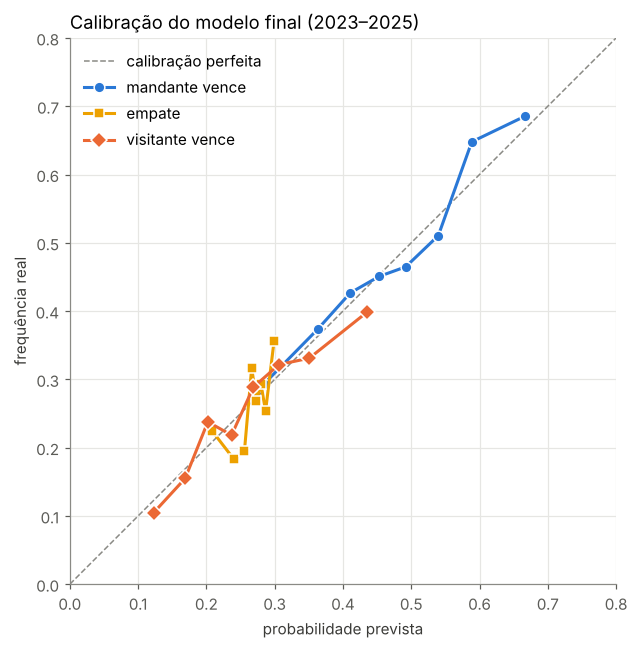

In [6]:
final = preds[preds["modelo"] == "Média (Dixon-Coles + Elo)"]
fig, ax = plt.subplots(figsize=(6.2, 6))
ax.plot([0, 0.8], [0, 0.8], color="#8a8a85", lw=1, ls="--", label="calibração perfeita")
for col, res_, nome, cor, mk in [("p_H", "H", "mandante vence", CORES[0], "o"), ("p_D", "D", "empate", CORES[3], "s"), ("p_A", "A", "visitante vence", CORES[1], "D")]:
    bins = pd.qcut(final[col], 8, duplicates="drop")
    g = final.assign(ok=(final["resultado"] == res_)).groupby(bins, observed=True).agg(prev=(col, "mean"), real=("ok", "mean"), n=("ok", "size"))
    ax.plot(g["prev"], g["real"], color=cor, marker=mk, label=nome, markeredgecolor="white")
ax.set_xlabel("probabilidade prevista"); ax.set_ylabel("frequência real")
ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8); ax.set_aspect("equal")
ax.set_title("Calibração do modelo final (2023–2025)", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("../results/calibracao.png", dpi=150); plt.show()

## Empates: o ponto fraco

O empate é o resultado mais difícil de prever em futebol. O modelo acerta a **frequência** de empates na média, mas nunca coloca o empate como resultado mais provável (0 de 1.140 jogos). Por isso a acurácia fica em ~50%, e as métricas de probabilidade (RPS, log-loss) são as que importam.

In [7]:
mais_provavel = final[["p_H", "p_D", "p_A"]].idxmax(axis=1)
print("Empates reais em 2023–2025:            ", f"{(final['resultado'] == 'D').mean():.1%}")
print("Probabilidade média de empate prevista:", f"{final['p_D'].mean():.1%}")
print("Maior probabilidade de empate prevista:", f"{final['p_D'].max():.1%}")
print("Jogos em que o empate era o mais provável:", (mais_provavel == "p_D").sum(), "de", len(final))

Empates reais em 2023–2025:             26.1%
Probabilidade média de empate prevista: 26.4%
Maior probabilidade de empate prevista: 32.3%
Jogos em que o empate era o mais provável: 0 de 1140
